# Clustering — Segmentation des stations d'épuration

Notebook de **clustering non-supervisé** pour segmenter les 1 533 STEU du parc Seine-Normandie en profils de performance homogènes.

**Méthodologie** :
1. Agrégation par station (1 ligne = 1 station, moyennes sur 24 mois)
2. Normalisation des features (StandardScaler)
3. Recherche du nombre optimal de clusters (silhouette score)
4. K-Means + Bisecting K-Means comparés
5. Visualisation PCA 2D + caractérisation des clusters

# 0. Imports & initialisation Spark

In [2]:
# ----- Python
import os

# ----- PySpark
from pyspark.sql.session import SparkSession
import pyspark.sql.functions as sf
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.clustering import KMeans, BisectingKMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.pipeline import Pipeline

# ----- Autres
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- Initialisation Spark
spark = (
    SparkSession.builder.appName('Projet_Clustering')
    .config('spark.driver.memory', '4g')
    .config('spark.executer.memory', '4g')
    .config('spark.sql.shuffle.partitions', '50')
    .config('spark.sql.execution.arrow.pyspark.enabaled', 'true')
    .getOrCreate()
)

# ----- Formatage du texte
B  = '\033[1m'
BE = '\033[0m'

# ----- Chemin vers les données
CHEMIN_INTERIM = '../data/interim'

# 1. Chargement des données

In [3]:
df_Feat = spark.read.parquet(CHEMIN_INTERIM + '/df_Feat.parquet')
print(f'{df_Feat.count():,} lignes (1 ligne = 1 prélèvement)')
df_Feat.printSchema()

2,024,836 lignes (1 ligne = 1 prélèvement)
root
 |-- CdSta: string (nullable = true)
 |-- NmNoSta: string (nullable = true)
 |-- DtPrel: string (nullable = true)
 |-- AnPrel: string (nullable = true)
 |-- MoPrel: string (nullable = true)
 |-- NoDep: string (nullable = true)
 |-- CdTpSta: string (nullable = true)
 |-- LbTpSta: string (nullable = true)
 |-- CapNomSta: double (nullable = true)
 |-- A3_Temperature: double (nullable = true)
 |-- A3_pH: double (nullable = true)
 |-- A3_MES: double (nullable = true)
 |-- A3_DBO5: double (nullable = true)
 |-- A3_DCO: double (nullable = true)
 |-- A3_NTK: double (nullable = true)
 |-- A3_NH4: double (nullable = true)
 |-- A3_NO2: double (nullable = true)
 |-- A3_NO3: double (nullable = true)
 |-- A3_PT: double (nullable = true)
 |-- A3_Nglobal: double (nullable = true)
 |-- A3_Volume: double (nullable = true)
 |-- A3_Pluie: double (nullable = true)
 |-- A4_Temperature: double (nullable = true)
 |-- A4_pH: double (nullable = true)
 |-- A4_MES: 

# 2. Agrégation par station

**Changement de granularité critique** : on passe de **1 prélèvement = 1 ligne** à **1 station = 1 ligne**.

Pour chaque station, on calcule :
- **Moyennes** des rendements (performance moyenne)
- **Écarts-types** des rendements (stabilité / variabilité)
- **Capacité nominale** (caractéristique fixe de la station)
- **Nombre de prélèvements** (volume de données disponibles)

In [7]:
df_Stations = (
    df_Feat
    .groupBy('CdSta')
    .agg(
        # Capacité (constante par station)
        sf.first('CapNomSta').alias('CapNomSta'),
        sf.first('CatSta').alias('CatSta'),
        sf.first('NoDep').alias('NoDep'),
        
        # Performances moyennes (5 polluants principaux)
        sf.avg('Rdt_DBO5').alias('Rdt_DBO5_moy'),
        sf.avg('Rdt_DCO').alias('Rdt_DCO_moy'),
        sf.avg('Rdt_MES').alias('Rdt_MES_moy'),
        sf.avg('Rdt_NTK').alias('Rdt_NTK_moy'),
        sf.avg('Rdt_PT').alias('Rdt_PT_moy'),
        
        # Variabilité (stddev)
        sf.stddev('Rdt_DBO5').alias('Rdt_DBO5_std'),
        sf.stddev('Rdt_DCO').alias('Rdt_DCO_std'),
        sf.stddev('Rdt_MES').alias('Rdt_MES_std'),
        
        # Sortie moyenne (qualité du rejet)
        sf.avg('A4_DBO5').alias('A4_DBO5_moy'),
        sf.avg('A4_DCO').alias('A4_DCO_moy'),
        sf.avg('A4_MES').alias('A4_MES_moy'),
        
        # Volume d'observations
        sf.count('*').alias('NbPrelevements'),
    )
)

print(f'{df_Stations.count():,} stations agrégées')
df_Stations.printSchema()

2,005 stations agrégées
root
 |-- CdSta: string (nullable = true)
 |-- CapNomSta: double (nullable = true)
 |-- CatSta: string (nullable = true)
 |-- NoDep: string (nullable = true)
 |-- Rdt_DBO5_moy: double (nullable = true)
 |-- Rdt_DCO_moy: double (nullable = true)
 |-- Rdt_MES_moy: double (nullable = true)
 |-- Rdt_NTK_moy: double (nullable = true)
 |-- Rdt_PT_moy: double (nullable = true)
 |-- Rdt_DBO5_std: double (nullable = true)
 |-- Rdt_DCO_std: double (nullable = true)
 |-- Rdt_MES_std: double (nullable = true)
 |-- A4_DBO5_moy: double (nullable = true)
 |-- A4_DCO_moy: double (nullable = true)
 |-- A4_MES_moy: double (nullable = true)
 |-- NbPrelevements: long (nullable = false)



# 3. Sélection des features de clustering & nettoyage

On garde les features qui décrivent la **performance** d'une station :
- Moyennes des 3 rendements principaux (DBO5, DCO, MES)
- Variabilités des 3 rendements
- Capacité nominale (taille)

On supprime les stations avec NULL pour avoir un dataset propre.

In [10]:
features_clust = [
    'Rdt_DBO5_moy', 'Rdt_DCO_moy', 'Rdt_MES_moy',
    'Rdt_DBO5_std', 'Rdt_DCO_std', 'Rdt_MES_std',
    'CapNomSta'
]

df_Clust = df_Stations.dropna(subset=features_clust)

print(f'Avant nettoyage : {df_Stations.count():,} stations')
print(f'Après nettoyage : {df_Clust.count():,} stations')
df_Clust.select(features_clust).describe().show()

Avant nettoyage : 2,005 stations
Après nettoyage : 1,874 stations
+-------+-----------------+------------------+-------------------+------------------+--------------------+--------------------+-----------------+
|summary|     Rdt_DBO5_moy|       Rdt_DCO_moy|        Rdt_MES_moy|      Rdt_DBO5_std|         Rdt_DCO_std|         Rdt_MES_std|        CapNomSta|
+-------+-----------------+------------------+-------------------+------------------+--------------------+--------------------+-----------------+
|  count|             1874|              1874|               1874|              1874|                1874|                1874|             1874|
|   mean|95.62209312248179| 90.90084198280955|  91.35545593605278|4.5516052944262935|   6.490439481094699|   8.806004001571804|14617.78121664888|
| stddev|7.235788407726775| 9.476912790536932| 13.820573309891591| 8.593175251244292|   9.516996581332956|  14.365847451088642|197721.2807630664|
|    min|8.583850931677018|-15.21584116593824|-30.35714285

# 4. Pipeline d'assemblage et normalisation

**StandardScaler** est CRITIQUE ici : `CapNomSta` peut aller de 100 à 500 000 EH, alors que les rendements sont entre 0 et 100 %. Sans normalisation, K-Means donnerait toute l'importance à la capacité.

In [12]:
# Vector Assembler
assembleur = VectorAssembler(inputCols=features_clust, outputCol='features_brutes')

# Standard Scaler (centre-réduit chaque feature : moyenne=0, stddev=1)
scaler = StandardScaler(
    inputCol='features_brutes',
    outputCol='features',
    withMean=True,
    withStd=True
)

# Pipeline complet
pipeline_prep = Pipeline(stages=[assembleur, scaler])
df_ClustScaled = pipeline_prep.fit(df_Clust).transform(df_Clust)

df_ClustScaled.select('CdSta', 'features').show(3, truncate=False)

+------------+----------------------------------------------------------------------------------------------------------------------------------------------+
|CdSta       |features                                                                                                                                      |
+------------+----------------------------------------------------------------------------------------------------------------------------------------------+
|030203702000|[0.38424941370430327,0.47262208350502244,0.49199653549232736,-0.4433277084560232,-0.5198468116422894,-0.5168244312375144,-0.06078142509632045]|
|030218001000|[0.440735034578708,0.45834254496894306,0.45674210985617925,-0.4722516520576884,-0.5288109298320928,-0.5078781689681987,-0.07013803047971817]  |
|031402201000|[0.04548921752958345,-0.8539493502301053,-1.3629643997499432,0.0030870938675284327,0.7595510493186725,2.0989657871063243,-0.04358550168899491]|
+------------+--------------------------------------

# 5. Recherche du nombre optimal de clusters (silhouette score)

On teste **k = 2 à 10** et on choisit le k qui maximise le **silhouette score** (mesure la qualité du clustering : plus c'est proche de 1, mieux c'est).

In [14]:
silhouettes = []

evaluator = ClusteringEvaluator(featuresCol='features', metricName='silhouette')

for k in range(2, 11):
    kmeans = KMeans(featuresCol='features', k=k, seed=2026)
    model = kmeans.fit(df_ClustScaled)
    pred = model.transform(df_ClustScaled)
    score = evaluator.evaluate(pred)
    silhouettes.append({'k': k, 'silhouette': score, 'wssse': model.summary.trainingCost})
    print(f'k={k} | silhouette={score:.4f} | WSSSE={model.summary.trainingCost:.0f}')

df_sil = pd.DataFrame(silhouettes)

k=2 | silhouette=0.8628 | WSSSE=7440
k=3 | silhouette=0.8743 | WSSSE=6006
k=4 | silhouette=0.6686 | WSSSE=5417
k=5 | silhouette=0.6031 | WSSSE=4992
k=6 | silhouette=0.7127 | WSSSE=3720
k=7 | silhouette=0.6901 | WSSSE=3418
k=8 | silhouette=0.7148 | WSSSE=3264
k=9 | silhouette=0.5144 | WSSSE=2950
k=10 | silhouette=0.4663 | WSSSE=2695


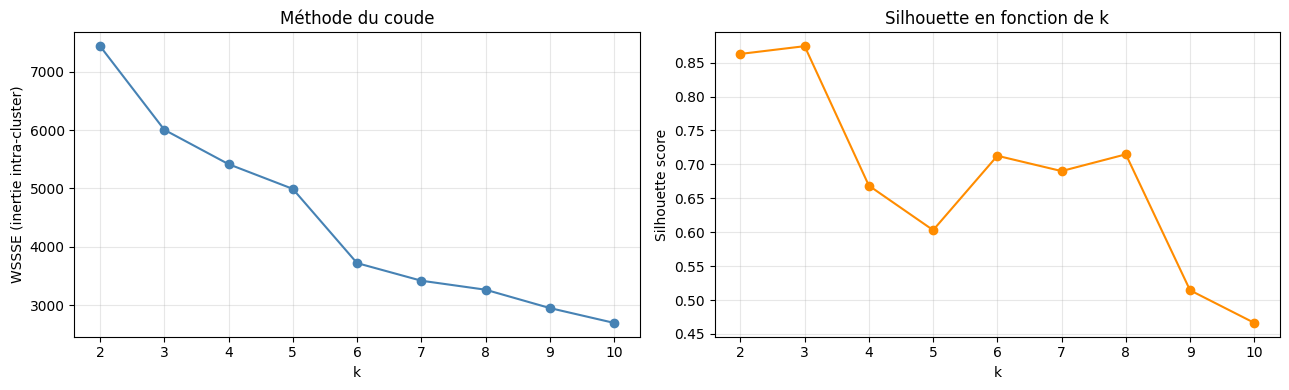


k optimal (silhouette max) : 3


In [17]:
# Visualisation : courbe du coude (WSSSE) + silhouette
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(df_sil['k'], df_sil['wssse'], 'o-', color='steelblue')
axes[0].set_xlabel('k')
axes[0].set_ylabel('WSSSE (inertie intra-cluster)')
axes[0].set_title('Méthode du coude')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_sil['k'], df_sil['silhouette'], 'o-', color='darkorange')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette en fonction de k')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Choix du k optimal
k_opt = int(df_sil.loc[df_sil['silhouette'].idxmax(), 'k'])
print(f'\n{B}k optimal (silhouette max) : {k_opt}{BE}')

# 6. K-Means avec k optimal

In [19]:
kmeans = KMeans(featuresCol='features', k=k_opt, seed=2026)
kmeans_model = kmeans.fit(df_ClustScaled)
df_KM = kmeans_model.transform(df_ClustScaled).withColumnRenamed('prediction', 'cluster_KM')

# Silhouette finale
sil_KM = ClusteringEvaluator(featuresCol='features', predictionCol='cluster_KM').evaluate(df_KM)
print(f'{B}K-Means (k={k_opt}){BE} | Silhouette = {sil_KM:.4f}')

# Distribution des clusters
df_KM.groupBy('cluster_KM').count().orderBy('cluster_KM').show()

K-Means (k=3) | Silhouette = 0.8743
+----------+-----+
|cluster_KM|count|
+----------+-----+
|         0| 1713|
|         1|  160|
|         2|    1|
+----------+-----+



# 7. Bisecting K-Means (comparaison)

In [21]:
bkm = BisectingKMeans(featuresCol='features', k=k_opt, seed=2026)
bkm_model = bkm.fit(df_ClustScaled)
df_BKM = bkm_model.transform(df_ClustScaled).withColumnRenamed('prediction', 'cluster_BKM')

# Silhouette
sil_BKM = ClusteringEvaluator(featuresCol='features', predictionCol='cluster_BKM').evaluate(df_BKM)
print(f'{B}Bisecting K-Means (k={k_opt}){BE} | Silhouette = {sil_BKM:.4f}')

df_BKM.groupBy('cluster_BKM').count().orderBy('cluster_BKM').show()

# Comparaison
print(f'\n{B}--- Comparaison ---{BE}')
print(f'K-Means          : {sil_KM:.4f}')
print(f'Bisecting KMeans : {sil_BKM:.4f}')
print(f'Meilleur         : {"K-Means" if sil_KM > sil_BKM else "Bisecting K-Means"}')

Bisecting K-Means (k=3) | Silhouette = 0.5440
+-----------+-----+
|cluster_BKM|count|
+-----------+-----+
|          0|  160|
|          1|  311|
|          2| 1403|
+-----------+-----+


--- Comparaison ---
K-Means          : 0.8743
Bisecting KMeans : 0.5440
Meilleur         : K-Means


# 8. Caractérisation des clusters (profils métier)

Pour chaque cluster, on calcule les **moyennes des features originales** (avant scaling) pour comprendre le profil de chaque groupe.

In [23]:
# Joindre cluster KMeans aux données originales
df_Profils = (
    df_KM
    .groupBy('cluster_KM')
    .agg(
        sf.count('*').alias('NbStations'),
        sf.round(sf.avg('Rdt_DBO5_moy'), 2).alias('Rdt_DBO5_moy'),
        sf.round(sf.avg('Rdt_DCO_moy'), 2).alias('Rdt_DCO_moy'),
        sf.round(sf.avg('Rdt_MES_moy'), 2).alias('Rdt_MES_moy'),
        sf.round(sf.avg('Rdt_DBO5_std'), 2).alias('Variabilite_DBO5'),
        sf.round(sf.avg('CapNomSta'), 0).alias('Capacite_moy'),
    )
    .orderBy('cluster_KM')
)

df_Profils.show(truncate=False)

+----------+----------+------------+-----------+-----------+----------------+------------+
|cluster_KM|NbStations|Rdt_DBO5_moy|Rdt_DCO_moy|Rdt_MES_moy|Variabilite_DBO5|Capacite_moy|
+----------+----------+------------+-----------+-----------+----------------+------------+
|0         |1713      |97.23       |93.08      |94.39      |2.76            |11485.0     |
|1         |160       |78.37       |67.55      |58.86      |23.76           |1377.0      |
|2         |1         |94.22       |89.27      |95.1       |3.94            |7500000.0   |
+----------+----------+------------+-----------+-----------+----------------+------------+



# 9. Visualisation PCA 2D

Pour visualiser les clusters dans un espace 2D, on réduit les 7 dimensions à 2 via **Principal Component Analysis**.

In [25]:
# PCA en 2 dimensions
pca = PCA(k=2, inputCol='features', outputCol='pca_features')
pca_model = pca.fit(df_KM)
df_PCA = pca_model.transform(df_KM)

# Variance expliquée par les 2 composantes
var_explained = pca_model.explainedVariance.toArray()
print(f'Variance expliquée par PC1 : {var_explained[0]*100:.1f}%')
print(f'Variance expliquée par PC2 : {var_explained[1]*100:.1f}%')
print(f'Total                      : {sum(var_explained)*100:.1f}%')

# Conversion en pandas pour matplotlib
df_pd = df_PCA.select('cluster_KM', 'pca_features').toPandas()
df_pd['PC1'] = df_pd['pca_features'].apply(lambda v: v[0])
df_pd['PC2'] = df_pd['pca_features'].apply(lambda v: v[1])

Variance expliquée par PC1 : 63.2%
Variance expliquée par PC2 : 14.3%
Total                      : 77.5%


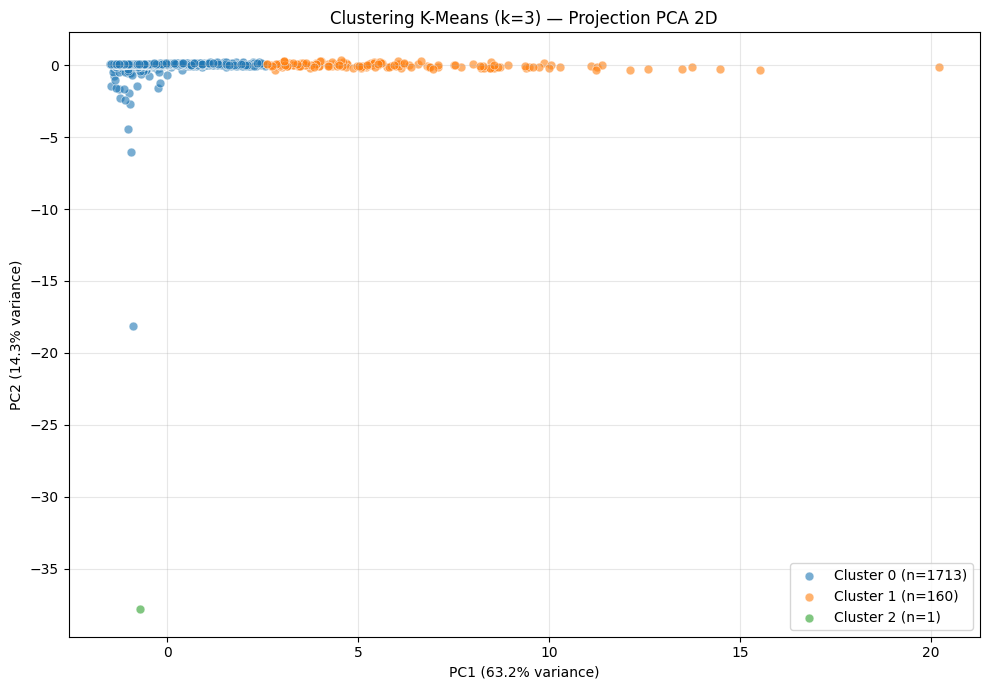

In [26]:
# Visualisation
plt.figure(figsize=(10, 7))
colors = plt.cm.tab10.colors

for c in sorted(df_pd['cluster_KM'].unique()):
    sub = df_pd[df_pd['cluster_KM'] == c]
    plt.scatter(sub['PC1'], sub['PC2'], 
                c=[colors[c]], label=f'Cluster {c} (n={len(sub)})',
                alpha=0.6, s=40, edgecolors='white', linewidth=0.5)

plt.xlabel(f'PC1 ({var_explained[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({var_explained[1]*100:.1f}% variance)')
plt.title(f'Clustering K-Means (k={k_opt}) — Projection PCA 2D')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
df_KM.select('CdSta','CapNomSta','CatSta','NoDep','cluster_KM').groupBy('cluster_KM','CatSta').count().orderBy('count',ascending = False).show()

+----------+-------+-----+
|cluster_KM| CatSta|count|
+----------+-------+-----+
|         0| petite| 1018|
|         0|moyenne|  487|
|         0| grande|  208|
|         1| petite|  149|
|         1|moyenne|    8|
|         1| grande|    3|
|         2| grande|    1|
+----------+-------+-----+



In [28]:
df_KM.groupBy('cluster_KM').agg(
    sf.count('*').alias('NbStations'),
    sf.round(sf.avg('Rdt_DBO5_moy'), 2).alias('Rdt_DBO5'),
    sf.round(sf.avg('CapNomSta'), 0).alias('Capacite_moy'),
).orderBy('cluster_KM').show()

+----------+----------+--------+------------+
|cluster_KM|NbStations|Rdt_DBO5|Capacite_moy|
+----------+----------+--------+------------+
|         0|      1713|   97.23|     11485.0|
|         1|       160|   78.37|      1377.0|
|         2|         1|   94.22|   7500000.0|
+----------+----------+--------+------------+



In [29]:
# Boucle sur tous les clusters pour voir un échantillon
for c in range(k_opt):
    print(f'\n{B}=== Cluster {c} — exemples ==={BE}')
    df_KM.filter(sf.col('cluster_KM') == c) \
         .select('CdSta', 'NoDep', 'CapNomSta', 'CatSta', 'Rdt_DBO5_moy') \
         .orderBy(sf.desc('CapNomSta')) \
         .show(5, truncate=False)


=== Cluster 0 — exemples ===
+------------+-----+---------+------+-----------------+
|CdSta       |NoDep|CapNomSta|CatSta|Rdt_DBO5_moy     |
+------------+-----+---------+------+-----------------+
|039407401000|94   |3600000.0|grande|97.83621303361598|
|037862401000|78   |1211667.0|grande|97.10611477757351|
|039202501000|92   |900000.0 |grande|97.3025787139501 |
|039305101000|93   |550000.0 |grande|97.20244001344695|
|037649801000|76   |500000.0 |grande|98.10884872311726|
+------------+-----+---------+------+-----------------+
only showing top 5 rows

=== Cluster 1 — exemples ===
+------------+-----+---------+-------+-----------------+
|CdSta       |NoDep|CapNomSta|CatSta |Rdt_DBO5_moy     |
+------------+-----+---------+-------+-----------------+
|037632201000|76   |58300.0  |grande |90.62072180824488|
|037851701000|78   |40000.0  |grande |90.22563935727709|
|037734401000|77   |10000.0  |grande |92.13980283316313|
|037625401000|76   |4700.0   |moyenne|85.0370088068429 |
|032703803000

In [30]:
# Tableau des profils en valeurs réelles
profils_pd = (
    df_KM
    .groupBy('cluster_KM')
    .agg(
        sf.count('*').alias('NbStations'),
        sf.round(sf.avg('Rdt_DBO5_moy'), 2).alias('Rdt_DBO5'),
        sf.round(sf.avg('Rdt_DCO_moy'), 2).alias('Rdt_DCO'),
        sf.round(sf.avg('Rdt_MES_moy'), 2).alias('Rdt_MES'),
        sf.round(sf.avg('Rdt_DBO5_std'), 2).alias('Var_DBO5'),
        sf.round(sf.avg('Rdt_DCO_std'), 2).alias('Var_DCO'),
        sf.round(sf.avg('Rdt_MES_std'), 2).alias('Var_MES'),
        sf.round(sf.avg('CapNomSta'), 0).alias('Capacite'),
    )
    .orderBy('cluster_KM')
    .toPandas()
)

print(profils_pd.to_string(index=False))

 cluster_KM  NbStations  Rdt_DBO5  Rdt_DCO  Rdt_MES  Var_DBO5  Var_DCO  Var_MES  Capacite
          0        1713     97.23    93.08    94.39      2.76     4.50     5.77   11485.0
          1         160     78.37    67.55    58.86     23.76    27.81    41.29    1377.0
          2           1     94.22    89.27    95.10      3.94     4.34     3.58 7500000.0


## 10. Heatmap des profils

**Lecture la plus rapide** : une cellule = un cluster × une feature, couleur = valeur normalisée.

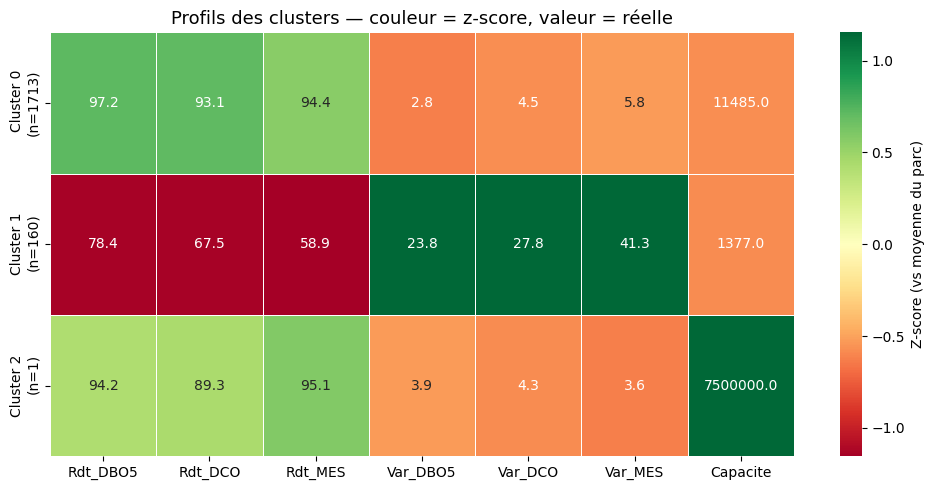

In [32]:
import seaborn as sns

# Pour la heatmap : normaliser par feature (z-score) pour comparer entre clusters
features_viz = ['Rdt_DBO5', 'Rdt_DCO', 'Rdt_MES', 'Var_DBO5', 'Var_DCO', 'Var_MES', 'Capacite']

heat_data = profils_pd[features_viz].copy()

# Normalisation z-score colonne par colonne pour rendre comparable
heat_data_norm = (heat_data - heat_data.mean()) / heat_data.std()
heat_data_norm.index = [f'Cluster {c}\n(n={n})' for c, n in zip(profils_pd['cluster_KM'], profils_pd['NbStations'])]

# Heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(
    heat_data_norm,
    annot=heat_data.values,    # affiche les vraies valeurs
    fmt='.1f',
    cmap='RdYlGn',
    center=0,
    cbar_kws={'label': 'Z-score (vs moyenne du parc)'},
    linewidths=0.5
)
plt.title('Profils des clusters — couleur = z-score, valeur = réelle', fontsize=13)
plt.tight_layout()
plt.savefig('../reports/figures/clusters_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Graphes radar (un par cluster)

**Très visuel** pour le rapport. Chaque cluster a sa propre forme caractéristique.

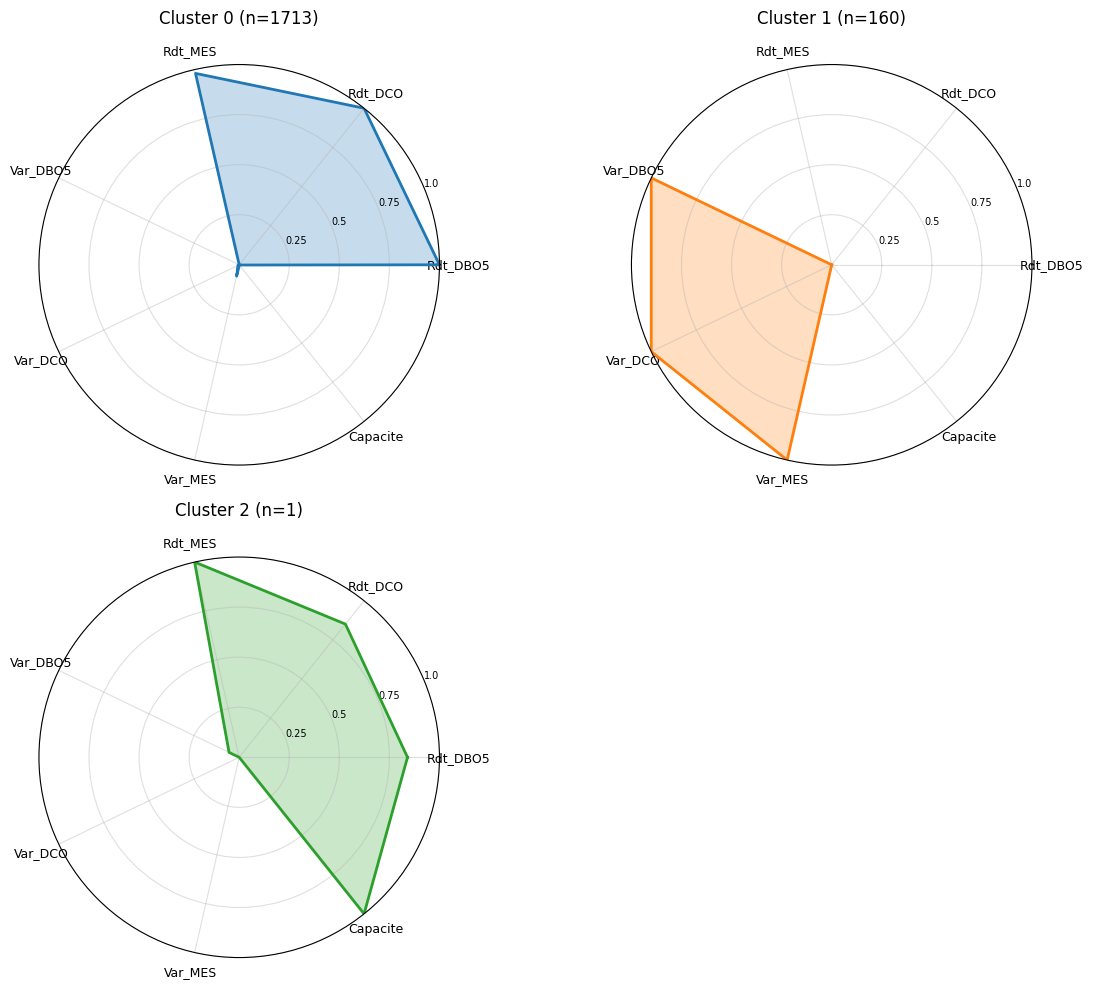

In [34]:
import numpy as np

# Préparation : on normalise les features sur [0,1] pour le radar
features_radar = ['Rdt_DBO5', 'Rdt_DCO', 'Rdt_MES', 'Var_DBO5', 'Var_DCO', 'Var_MES', 'Capacite']
radar_data = profils_pd[features_radar].copy()

# Normalisation min-max pour le radar (0 à 1)
radar_norm = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min())

# Angles pour les axes du radar
N = len(features_radar)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # boucle fermée

# Subplot grid (2x2 si k=4, à ajuster)
n_clusters = len(profils_pd)
n_cols = 2
n_rows = (n_clusters + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5*n_rows), subplot_kw=dict(projection='polar'))
axes = axes.flatten() if n_clusters > 1 else [axes]

colors = plt.cm.tab10.colors

for i, (idx, row) in enumerate(radar_norm.iterrows()):
    values = row.tolist() + row.tolist()[:1]  # boucle fermée
    
    ax = axes[i]
    ax.plot(angles, values, color=colors[i], linewidth=2)
    ax.fill(angles, values, color=colors[i], alpha=0.25)
    
    # Axes
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(features_radar, size=9)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['0.25', '0.5', '0.75', '1.0'], size=7)
    
    cluster_id = profils_pd.loc[idx, 'cluster_KM']
    nb_st = profils_pd.loc[idx, 'NbStations']
    ax.set_title(f'Cluster {cluster_id} (n={nb_st})', size=12, pad=15)
    ax.grid(True, alpha=0.4)

# Cacher les subplots vides s'il y en a
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/clusters_radar.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Boxplots — Distribution réelle des features par cluster

Permet de voir la **dispersion** dans chaque cluster (pas juste la moyenne).

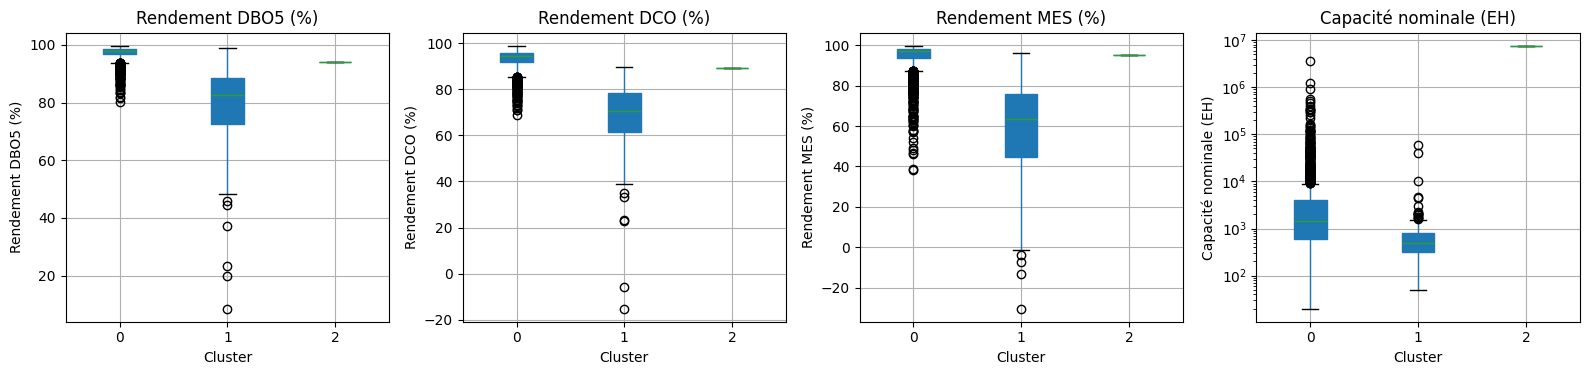

In [36]:
# Récupérer toutes les stations avec leur cluster + features
df_box_pd = (
    df_KM
    .select('cluster_KM', 'Rdt_DBO5_moy', 'Rdt_DCO_moy', 'Rdt_MES_moy', 'CapNomSta')
    .toPandas()
)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
features_box = [
    ('Rdt_DBO5_moy', 'Rendement DBO5 (%)'),
    ('Rdt_DCO_moy',  'Rendement DCO (%)'),
    ('Rdt_MES_moy',  'Rendement MES (%)'),
    ('CapNomSta',    'Capacité nominale (EH)'),
]

for ax, (col, titre) in zip(axes, features_box):
    df_box_pd.boxplot(column=col, by='cluster_KM', ax=ax, grid=True, patch_artist=True)
    ax.set_xlabel('Cluster')
    ax.set_ylabel(titre)
    ax.set_title(titre)
    if col == 'CapNomSta':
        ax.set_yscale('log')   # log pour la capacité (très étendue)

plt.suptitle('')   # supprimer le titre auto de pandas
plt.tight_layout()
plt.savefig('../reports/figures/clusters_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

# 13. Sauvegarde et conclusion

In [38]:
df_KM.select('CdSta', 'cluster_KM').write.mode('overwrite') \
     .parquet(CHEMIN_INTERIM + '/df_Clusters.parquet')
print('✅ Clusters sauvegardés.')

✅ Clusters sauvegardés.


In [54]:
spark.stop()